In [ ]:
!apt-get update
!apt-get install -y libopencv-dev build-essential cmake

Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Hit:2 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease
Hit:3 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease
Hit:4 http://archive.ubuntu.com/ubuntu noble InRelease
Hit:5 http://security.ubuntu.com/ubuntu noble-security InRelease
Hit:6 http://archive.ubuntu.com/ubuntu noble-updates InRelease
Hit:7 http://archive.ubuntu.com/ubuntu noble-backports InRelease
Hit:8 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease
Hit:9 https://r2u.stat.illinois.edu/ubuntu noble InRelease
Hit:10 https://ppa.launchpadcontent.net/graphics-drivers/ppa/ubuntu noble InRelease
Fetched 3,917 B in 1s (2,807 B/s)
Reading package lists... Done
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependen

In [ ]:
%%writefile main.cpp
#include <iostream>
#include <opencv2/opencv.hpp>
#include <cuda_runtime.h>

int main() {
    std::cout << "OpenCV Versiyonu: " << CV_VERSION << std::endl;

    // Colab GPU Bağlantı Kontrolü
    int deviceCount = 0;
    cudaError_t error = cudaGetDeviceCount(&deviceCount);

    if (error == cudaSuccess && deviceCount > 0) {
        std::cout << "Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: " << deviceCount << std::endl;
    } else {
        std::cout << "CUDA Cihazı Bulunamadı veya GPU Aktif Edilmedi!" << std::endl;
    }

    return 0;
}

Overwriting main.cpp


In [ ]:
!g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart
!./app

OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


In [ ]:
%%writefile setup.sh
#!/bin/bash
echo "[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor..."
apt-get update -qq && apt-get install -y -qq libopencv-dev build-essential cmake > /dev/null

echo "[2/3] C++ uygulaması derleniyor..."
g++ main.cpp -o app `pkg-config --cflags --libs opencv4` -I/usr/local/cuda/include -L/usr/local/cuda/lib64 -lcudart

echo "[3/3] Uygulama çalıştırılıyor..."
./app

Overwriting setup.sh


In [ ]:
!bash setup.sh

[1/3] Paket güncellemeleri ve OpenCV kurulumu yapılıyor...
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
[2/3] C++ uygulaması derleniyor...
[3/3] Uygulama çalıştırılıyor...
OpenCV Versiyonu: 4.6.0
Başarılı! Colab GPU (CUDA) Algılandı. Cihaz Sayısı: 1


Saving resim2.jpeg to resim2 (1).jpeg
Bulunan cember sayisi: 1


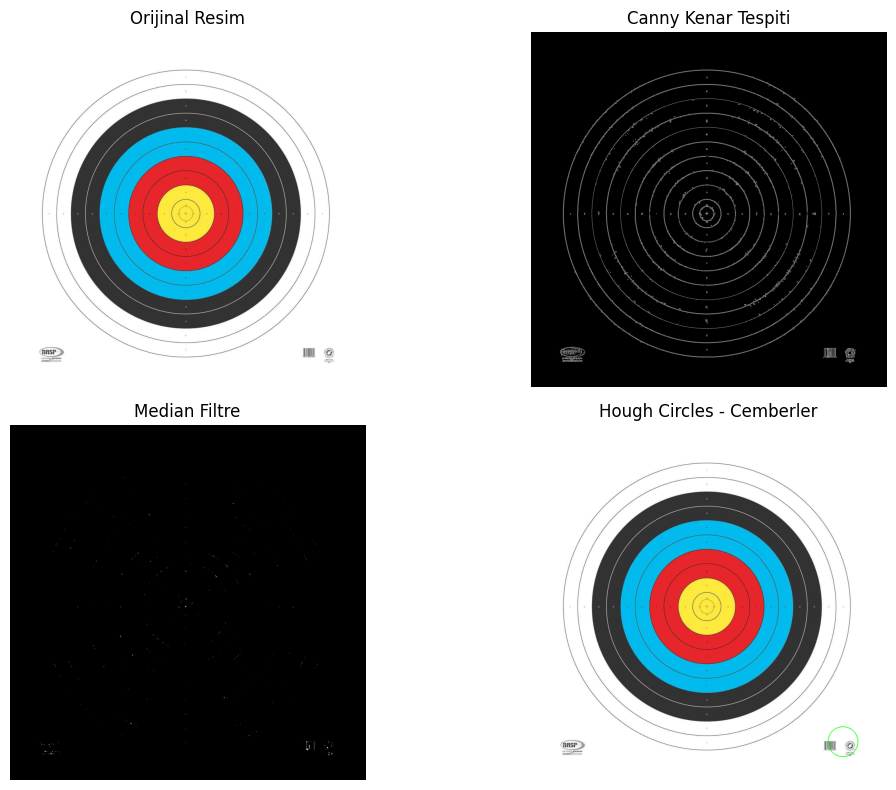

In [4]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# 1. Resmi yukle
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]

resim = cv2.imdecode(
    np.frombuffer(yuklenen[dosya_adi], np.uint8),
    cv2.IMREAD_COLOR
)

if resim is None:
    raise ValueError("Resim okunamadi!")

# 2. Resmi gri tona cevir
gri = cv2.cvtColor(resim, cv2.COLOR_BGR2GRAY)

# 3. Canny ile kenarlari bul
canny = cv2.Canny(gri, 50, 150)

# 4. Median filtre uygula
median = cv2.medianBlur(canny, 5)

# 5. Hough Circles ile cemberleri tespit et
cemberler = cv2.HoughCircles(
    median,
    cv2.HOUGH_GRADIENT,
    dp=1,
    minDist=30,
    param1=100,
    param2=15,
    minRadius=10,
    maxRadius=150
)

# 6. Cemberleri orijinal resme ciz
sonuc = resim.copy()

if cemberler is not None:
    cemberler = np.round(cemberler[0, :]).astype(int)

    for x, y, r in cemberler:
        cv2.circle(sonuc, (x, y), r, (0, 255, 0), 2)

    print("Bulunan cember sayisi:", len(cemberler))
else:
    print("Cember bulunamadi.")

# 7. Sonuclari goster
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(resim, cv2.COLOR_BGR2RGB))
plt.title("Orijinal Resim")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(canny, cmap="gray")
plt.title("Canny Kenar Tespiti")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(median, cmap="gray")
plt.title("Median Filtre")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.imshow(cv2.cvtColor(sonuc, cv2.COLOR_BGR2RGB))
plt.title("Hough Circles - Cemberler")
plt.axis("off")

plt.tight_layout()
plt.show()
